# Evidence-First Revenue Analyst
### An LLM tool-calling agent that clarifies, queries, and verifies sales answers

**Resume-ready project | Python · Jupyter · pandas · SQLite · OpenAI Responses API · LLM evaluation**

> Ask a sales question in plain English. The agent identifies what is missing, chooses a safe analytics tool, retrieves its result from SQLite, and returns a concise answer grounded in that result. A small benchmark checks whether the tool result and the final answer agree with known SQL outputs.

This project is intentionally connected to sales reporting work: it demonstrates how a data science co-op could make recurring questions easier to answer while keeping the calculation auditable. All bundled records are **synthetic and fictional**.

**Workflow:** `Question → Clarify if needed → Select approved tool → Query SQLite → Verify result → Answer with evidence`

The notebook has a deterministic, offline path and an optional live LLM path. The offline benchmark is reproducible without a key. Live API calls require the user's own API key and may incur usage charges.

## 1. Business problem and success criteria

Sales teams often ask recurring questions such as “Which region had the highest revenue last quarter?” The answer requires consistent definitions, accurate filtering, and a traceable calculation. A free-form LLM response can sound plausible while getting the number wrong.

**Design goals**
- Let an LLM select from narrowly defined, read-only Python tools backed by SQLite.
- Clarify an underspecified metric or time period instead of silently guessing.
- Keep SQL parameterized and restrict queries to prebuilt analytics functions.
- Return evidence (metric, filter, value, and row count) with each answer.
- Evaluate tool selection and answer numbers against independently computed SQL gold results.

**Success criteria:** offline benchmark tool-result accuracy and answer-number consistency; transparent clarification behavior; no arbitrary SQL execution.

## 2. Imports and reproducible data

The dataset is a seeded synthetic sales ledger created for this project. It has 2,400 order lines spanning 2024–2025, with product, category, region, channel, units, discount, revenue, cost, and profit. The CSV is included in the repository so the notebook does not need internet access.

In [1]:
from pathlib import Path
import json
import os
import re
import sqlite3
import pandas as pd

CURRENT_DIR = Path.cwd()
DATA_CANDIDATES = [
    CURRENT_DIR / "data" / "sales_orders.csv",                 # launched from project folder
    CURRENT_DIR / "sales_orders.csv",                           # CSV downloaded beside the notebook
    CURRENT_DIR / "evidence_first_revenue_analyst" / "data" / "sales_orders.csv",  # launched from repo parent
    Path.home() / "Downloads" / "sales_orders.csv",             # browser download default
]
CODEX_PROJECTS = Path.home() / "Documents" / "Codex"
if CODEX_PROJECTS.exists():
    DATA_CANDIDATES.extend(CODEX_PROJECTS.glob("**/evidence_first_revenue_analyst/data/sales_orders.csv"))
DATA_PATH = next((path.resolve() for path in DATA_CANDIDATES if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find sales_orders.csv. Extract the complete project ZIP, or download sales_orders.csv "
        "and place it in a data folder beside the notebook (or directly in the notebook's working folder)."
    )
PROJECT_DIR = DATA_PATH.parent.parent if DATA_PATH.parent.name.lower() == "data" else DATA_PATH.parent

sales = pd.read_csv(DATA_PATH, parse_dates=["order_date"])
sales.head()

,order_id,order_date,region,channel,product,category,units,unit_price,discount_pct,revenue,cost,profit
0,1,2024-07-27,Midwest,Retail,USB-C Hub,Electronics,3,86.92,0.00,260.76,162.0,98.76
1,2,2025-03-09,Northeast,Retail,Desk Lamp,Home,3,72.40,0.00,217.20,126.0,91.20
2,3,2024-01-07,South,Retail,Storage Set,Home,3,54.88,0.05,156.41,93.0,63.41
3,4,2024-05-27,Northeast,Retail,Storage Set,Home,1,62.51,0.00,62.51,31.0,31.51
4,5,2024-07-03,West,Partner,Wireless Mouse,Electronics,1,66.45,0.00,66.45,29.0,37.45


In [2]:
print(f"Rows: {len(sales):,} | Date range: {sales.order_date.min().date()} to {sales.order_date.max().date()}")
print("Missing values:", int(sales.isna().sum().sum()))
print("Duplicate order IDs:", int(sales.order_id.duplicated().sum()))
print("Revenue total:", f"${sales.revenue.sum():,.2f}")
sales.groupby("region", as_index=False).agg(orders=("order_id", "count"), revenue=("revenue", "sum")).sort_values("revenue", ascending=False)

Rows: 2,400 | Date range: 2024-01-01 to 2025-07-01
Missing values: 0
Duplicate order IDs: 0
Revenue total: $506,832.61


,region,orders,revenue
1,Northeast,582,135809.23
3,West,643,131640.13
0,Midwest,571,119928.68
2,South,604,119454.57


## 3. Visual exploration: geography, category, and trend

Interactive Plotly charts help a reviewer spot patterns quickly. The map places one marker at an **approximate center of each broad sales region**; marker size and color represent synthetic revenue. These are regional summaries, not store or customer locations. Hover over markers and bars for the values.

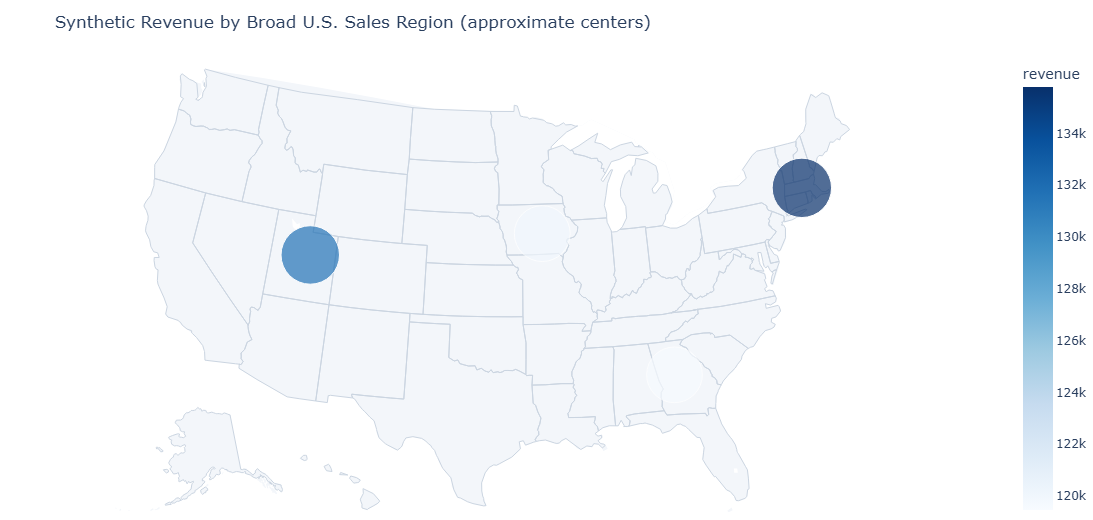

In [3]:
import plotly.express as px

region_summary = sales.groupby("region", as_index=False).agg(
    revenue=("revenue", "sum"), orders=("order_id", "nunique"), profit=("profit", "sum")
)
region_centers = {
    "Northeast": (42.3, -72.0),
    "South": (33.0, -84.0),
    "Midwest": (41.8, -93.0),
    "West": (39.7, -111.0),
}
region_summary["latitude"] = region_summary.region.map(lambda region: region_centers[region][0])
region_summary["longitude"] = region_summary.region.map(lambda region: region_centers[region][1])

fig = px.scatter_geo(
    region_summary, lat="latitude", lon="longitude", size="revenue", color="revenue",
    hover_name="region", hover_data={"revenue": ":$,.0f", "orders": True, "latitude": False, "longitude": False},
    scope="usa", projection="albers usa", size_max=42, color_continuous_scale="Blues",
    title="Synthetic Revenue by Broad U.S. Sales Region (approximate centers)"
)
fig.update_geos(showland=True, landcolor="#F3F6FA", showlakes=True, lakecolor="white",
                showsubunits=True, subunitcolor="#CBD5E1")
fig.update_layout(height=520, margin={"l": 0, "r": 0, "t": 55, "b": 0})
fig.show()

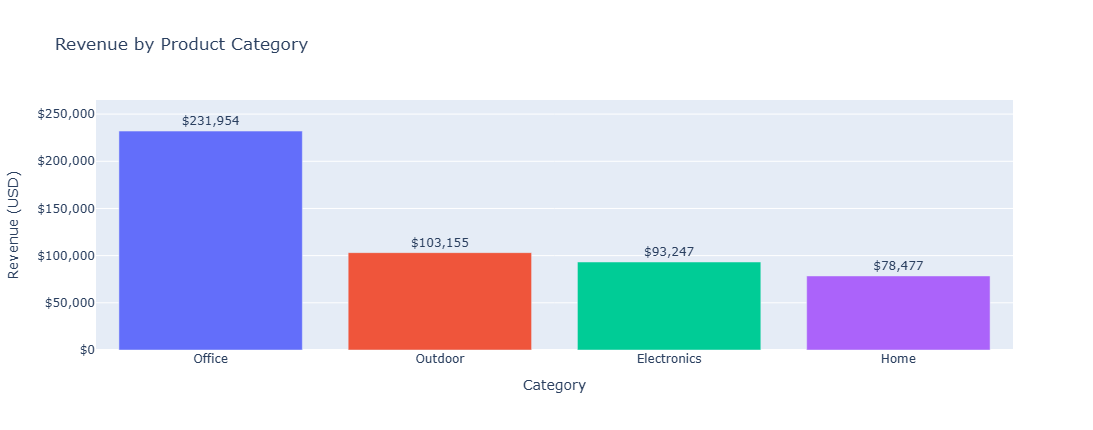

In [4]:
category_summary = sales.groupby("category", as_index=False).agg(
    revenue=("revenue", "sum"), profit=("profit", "sum"), orders=("order_id", "nunique")
)
category_summary["profit_margin_pct"] = 100 * category_summary.profit / category_summary.revenue
category_summary = category_summary.sort_values("revenue", ascending=False)

fig = px.bar(category_summary, x="category", y="revenue", color="category",
             hover_data={"profit": ":$,.2f", "orders": True, "profit_margin_pct": ":.1f"},
             title="Revenue by Product Category", labels={"revenue": "Revenue (USD)", "category": "Category"})
fig.update_traces(texttemplate="$%{y:,.0f}", textposition="outside")
fig.update_layout(showlegend=False, yaxis_tickprefix="$", yaxis_tickformat=",", height=430)
fig.show()

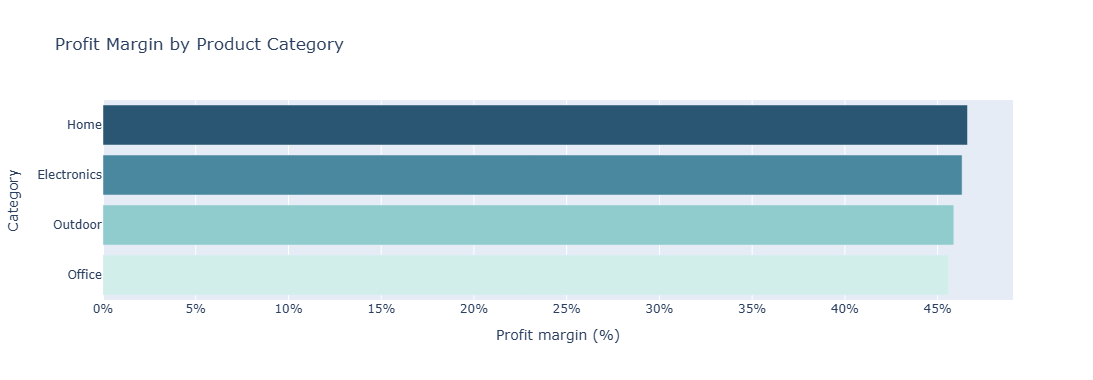

In [5]:
fig = px.bar(category_summary.sort_values("profit_margin_pct"), x="profit_margin_pct", y="category",
             orientation="h", color="profit_margin_pct", color_continuous_scale="Teal",
             hover_data={"profit": ":$,.2f", "revenue": ":$,.2f"},
             title="Profit Margin by Product Category", labels={"profit_margin_pct": "Profit margin (%)", "category": "Category"})
fig.update_layout(coloraxis_showscale=False, xaxis_ticksuffix="%", height=380)
fig.show()

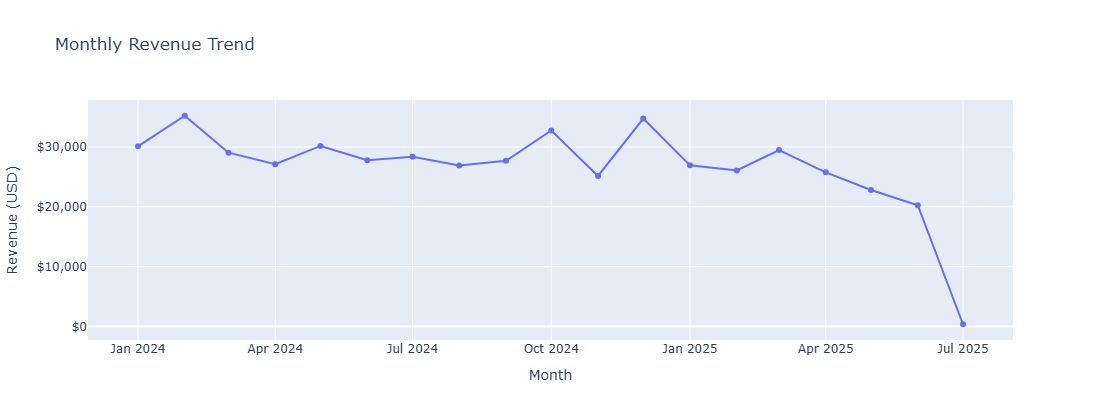

In [6]:
monthly_revenue = (sales.set_index("order_date").resample("MS")
                   .agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"))
                   .reset_index())
fig = px.line(monthly_revenue, x="order_date", y="revenue", markers=True,
              hover_data={"orders": True}, title="Monthly Revenue Trend",
              labels={"order_date": "Month", "revenue": "Revenue (USD)"})
fig.update_layout(yaxis_tickprefix="$", yaxis_tickformat=",", height=420)
fig.show()

## 4. Load an auditable SQLite analytics layer

The LLM never writes SQL. It can request only the approved `sales_summary` tool. That function validates arguments, applies SQL filters as parameters, and computes summaries using a fixed query. This is a smaller and easier-to-audit permission surface than unrestricted text-to-SQL.

In [7]:
DB_PATH = PROJECT_DIR / "sales_analytics.sqlite"
with sqlite3.connect(DB_PATH) as conn:
    sales.to_sql("sales_orders", conn, if_exists="replace", index=False)
    conn.execute("CREATE INDEX IF NOT EXISTS idx_sales_date ON sales_orders(order_date)")
    conn.execute("CREATE INDEX IF NOT EXISTS idx_sales_region ON sales_orders(region)")
    conn.execute("CREATE INDEX IF NOT EXISTS idx_sales_category ON sales_orders(category)")

ALLOWED_METRICS = {"revenue", "profit", "orders", "units"}
ALLOWED_GROUPS = {"region", "category", "channel", "month", None}
ALLOWED_FILTERS = {"region", "category", "channel", "start_date", "end_date"}
VALID_VALUES = {
    "region": set(sales.region.unique()),
    "category": set(sales.category.unique()),
    "channel": set(sales.channel.unique()),
}

def sales_summary(metric="revenue", group_by=None, filters=None):
    """Return a fixed, read-only sales summary; all user values are bound parameters."""
    filters = filters or {}
    if metric not in ALLOWED_METRICS:
        raise ValueError(f"Unsupported metric. Choose from {sorted(ALLOWED_METRICS)}.")
    if group_by not in ALLOWED_GROUPS:
        raise ValueError(f"Unsupported grouping. Choose from {sorted(x for x in ALLOWED_GROUPS if x)} or None.")
    unknown = set(filters) - ALLOWED_FILTERS
    if unknown:
        raise ValueError(f"Unsupported filters: {sorted(unknown)}")

    clauses, params = [], []
    for key in ("region", "category", "channel"):
        value = filters.get(key)
        if value is not None:
            if value not in VALID_VALUES[key]:
                raise ValueError(f"Unknown {key}: {value}")
            clauses.append(f"{key} = ?")
            params.append(value)
    if filters.get("start_date"):
        clauses.append("order_date >= ?")
        params.append(filters["start_date"])
    if filters.get("end_date"):
        clauses.append("order_date <= ?")
        params.append(filters["end_date"])
    where = " WHERE " + " AND ".join(clauses) if clauses else ""
    expression = {"revenue": "SUM(revenue)", "profit": "SUM(profit)",
                  "orders": "COUNT(DISTINCT order_id)", "units": "SUM(units)"}[metric]
    if group_by == "month":
        group_expr, label = "strftime('%Y-%m', order_date)", "month"
    elif group_by:
        group_expr, label = group_by, group_by
    else:
        group_expr, label = None, None
    if group_expr:
        sql = f"SELECT {group_expr} AS dimension, {expression} AS value, COUNT(*) AS row_count FROM sales_orders{where} GROUP BY dimension ORDER BY value DESC"
    else:
        sql = f"SELECT {expression} AS value, COUNT(*) AS row_count FROM sales_orders{where}"
    with sqlite3.connect(DB_PATH) as conn:
        result = pd.read_sql_query(sql, conn, params=params)
    return {"metric": metric, "group_by": label, "filters": filters,
            "records": result.to_dict(orient="records"), "row_count": int(result.row_count.sum()) if len(result) else 0}

sales_summary("revenue", group_by="region")

{'metric': 'revenue',
 'group_by': 'region',
 'filters': {},
 'records': [{'dimension': 'Northeast', 'value': 135809.23, 'row_count': 582},
  {'dimension': 'West', 'value': 131640.13, 'row_count': 643},
  {'dimension': 'Midwest', 'value': 119928.68, 'row_count': 571},
  {'dimension': 'South', 'value': 119454.57, 'row_count': 604}],
 'row_count': 2400}

## 5. Clarification-first workflow and prompt engineering

Before reaching the model, a small policy check catches missing scope. “How did sales do?” is ambiguous: it does not identify a metric or a period. The workflow asks a follow-up rather than inventing either. The prompt then instructs the model to use only the approved tool for numeric claims and to explain its filters.

In [8]:
def clarification_needed(question):
    q = question.lower()
    if not any(word in q for word in ("revenue", "profit", "order", "unit")):
        return "Which measure should I use: revenue, profit, order count, or units sold?"
    if any(term in q for term in ("last quarter", "this quarter", "last month", "this month", "year over year", "yoy")):
        return "This demo dataset has fixed dates, but relative periods are not configured. What exact start and end dates should I use?"
    return None

SYSTEM_PROMPT = """You are an evidence-first sales analytics assistant. You answer only questions about the supplied sales dataset.
Use the sales_summary tool for every numeric answer. Do not calculate or invent values from memory.
If the request is ambiguous, ask a concise clarification question before using a tool.
Choose only supported metrics, groupings, and filters. Explain the result using the tool output, state the applied filters, and distinguish order-line rows from distinct orders.
The dataset contains dates from 2024-01-01 through 2025-07-01. Do not interpret relative periods such as 'last quarter' without exact dates.
"""

def offline_route(question):
    """Deterministic demo route; makes agent decisions inspectable without an API key."""
    clarify = clarification_needed(question)
    if clarify:
        return {"status": "needs_clarification", "message": clarify, "tool": None}
    q = question.lower()
    metric = "profit" if "profit" in q else "orders" if "order" in q else "units" if "units" in q else "revenue"
    group = "month" if "month" in q or "monthly" in q else next((g for g in ("region", "category", "channel") if g in q), None)
    filters = {}
    for key, values in VALID_VALUES.items():
        for value in values:
            if value.lower() in q:
                filters[key] = value
    result = sales_summary(metric, group, filters)
    return {"status": "answered", "tool": "sales_summary", "tool_result": result}

print(offline_route("Compare revenue by region"))
print(offline_route("How did sales do?"))

{'status': 'answered', 'tool': 'sales_summary', 'tool_result': {'metric': 'revenue', 'group_by': 'region', 'filters': {}, 'records': [{'dimension': 'Northeast', 'value': 135809.23, 'row_count': 582}, {'dimension': 'West', 'value': 131640.13, 'row_count': 643}, {'dimension': 'Midwest', 'value': 119928.68, 'row_count': 571}, {'dimension': 'South', 'value': 119454.57, 'row_count': 604}], 'row_count': 2400}}
{'status': 'needs_clarification', 'message': 'Which measure should I use: revenue, profit, order count, or units sold?', 'tool': None}


## 6. Optional live LLM agent with function calling

Set `OPENAI_API_KEY` and `OPENAI_MODEL` in your environment to enable this section. The model chooses arguments for a named function; Python validates the request and executes the query. The function-call loop is capped at three turns. The API key stays outside the notebook and must never be committed to GitHub.

The call pattern follows the [OpenAI function-calling guide](https://platform.openai.com/docs/guides/function-calling): pass tools to the Responses API, execute returned function calls in application code, send `function_call_output`, and let the model produce the final response.

In [9]:
TOOL_SCHEMA = [{
    "type": "function",
    "name": "sales_summary",
    "description": "Query approved aggregate sales metrics from the SQLite dataset. Use for every numeric answer.",
    "parameters": {
        "type": "object", "additionalProperties": False,
        "properties": {
            "metric": {"type": "string", "enum": ["revenue", "profit", "orders", "units"]},
            "group_by": {"type": ["string", "null"], "enum": ["region", "category", "channel", "month", None]},
            "filters": {
                "type": "object", "additionalProperties": False,
                "properties": {
                    "region": {"type": ["string", "null"], "enum": sorted(VALID_VALUES["region"]) + [None]},
                    "category": {"type": ["string", "null"], "enum": sorted(VALID_VALUES["category"]) + [None]},
                    "channel": {"type": ["string", "null"], "enum": sorted(VALID_VALUES["channel"]) + [None]},
                    "start_date": {"type": ["string", "null"]},
                    "end_date": {"type": ["string", "null"]}
                }, "required": ["region", "category", "channel", "start_date", "end_date"]
            }
        }, "required": ["metric", "group_by", "filters"]
    }, "strict": True
}]

def live_agent(question, max_tool_rounds=3):
    if clarification_needed(question):
        return {"status": "needs_clarification", "message": clarification_needed(question), "tool_calls": [], "answer": None}
    from openai import OpenAI
    client = OpenAI()
    model = os.environ.get("OPENAI_MODEL")
    if not model:
        raise ValueError("Set OPENAI_MODEL to a model available to your API account.")
    conversation = [{"role": "user", "content": question}]
    tool_trace = []
    for _ in range(max_tool_rounds):
        response = client.responses.create(model=model, instructions=SYSTEM_PROMPT,
                                           tools=TOOL_SCHEMA, input=conversation)
        conversation += response.output
        calls = [item for item in response.output if item.type == "function_call"]
        if not calls:
            return {"status": "answered", "answer": response.output_text,
                    "tool_calls": tool_trace, "response_id": response.id}
        for call in calls:
            if call.name != "sales_summary":
                raise ValueError(f"Tool not allowed: {call.name}")
            args = json.loads(call.arguments)
            result = sales_summary(args["metric"], args["group_by"], args["filters"])
            tool_trace.append({"name": call.name, "arguments": args, "result": result})
            conversation.append({"type": "function_call_output", "call_id": call.call_id,
                                 "output": json.dumps(result)})
    return {"status": "max_tool_rounds_reached", "answer": None, "tool_calls": tool_trace}

API_READY = bool(os.environ.get("OPENAI_API_KEY") and os.environ.get("OPENAI_MODEL"))
print("Live agent available:", API_READY)

Live agent available: False


## 7. Gold benchmark: evaluate the tool result and final answer

Each benchmark question has an expected tool call and an independently calculated gold value from pandas over the source CSV. The agent tool result comes from SQLite, so the expected and actual values follow separate calculation paths. The offline router gives a repeatable baseline. When the live API is configured, the same questions also evaluate model tool selection and compare the answer's numeric claims to the gold value.

**Scores:** `tool_result_exact` checks the returned SQLite aggregate against the pandas gold value; `answer_contains_gold` checks whether a live answer includes the gold number (with common formatting); `tool_selection_accuracy` checks tool name, metric, grouping, and filters. A number-presence check is deliberately simple and should be extended with a structured-answer grader before production use.

In [10]:
BENCHMARK = [
    {"question": "What is total revenue?", "metric": "revenue", "group_by": None, "filters": {}, "record_index": 0},
    {"question": "Compare revenue by region", "metric": "revenue", "group_by": "region", "filters": {}, "record_index": 0},
    {"question": "Which category has the most profit?", "metric": "profit", "group_by": "category", "filters": {}, "record_index": 0},
    {"question": "How many orders came from the Online channel?", "metric": "orders", "group_by": None, "filters": {"channel": "Online"}, "record_index": 0},
    {"question": "How many units were sold in the West?", "metric": "units", "group_by": None, "filters": {"region": "West"}, "record_index": 0},
    {"question": "Show monthly revenue", "metric": "revenue", "group_by": "month", "filters": {}, "record_index": 0},
    {"question": "What is Northeast profit?", "metric": "profit", "group_by": None, "filters": {"region": "Northeast"}, "record_index": 0},
    {"question": "Compare orders by sales channel", "metric": "orders", "group_by": "channel", "filters": {}, "record_index": 0},
]

def normalize_number(value):
    return round(float(value), 2) if isinstance(value, (float, int)) else value

def normalize_filters(filters):
    return {key: value for key, value in (filters or {}).items() if value is not None}

def pandas_gold(metric, group_by=None, filters=None):
    """Independent reference result from the source DataFrame, not the SQLite tool."""
    frame = sales.copy()
    filters = filters or {}
    for column in ("region", "category", "channel"):
        if filters.get(column) is not None:
            frame = frame[frame[column] == filters[column]]
    if filters.get("start_date"):
        frame = frame[frame.order_date >= pd.Timestamp(filters["start_date"])]
    if filters.get("end_date"):
        frame = frame[frame.order_date <= pd.Timestamp(filters["end_date"])]

    def aggregate(part):
        if metric == "revenue": return round(float(part.revenue.sum()), 2)
        if metric == "profit": return round(float(part.profit.sum()), 2)
        if metric == "orders": return int(part.order_id.nunique())
        if metric == "units": return int(part.units.sum())
        raise ValueError(f"Unsupported metric in gold benchmark: {metric}")

    if group_by is None:
        return [{"value": aggregate(frame)}]
    dimension = frame.order_date.dt.strftime("%Y-%m") if group_by == "month" else frame[group_by]
    rows = [{"dimension": str(key), "value": aggregate(part)}
            for key, part in frame.assign(_dimension=dimension).groupby("_dimension", dropna=False, sort=False)]
    return sorted(rows, key=lambda row: row["value"], reverse=True)

def answer_mentions_value(answer, value, metric):
    if answer is None:
        return False
    if metric in {"revenue", "profit"}:
        candidates = {f"{float(value):,.2f}", f"{float(value):,.0f}", f"{float(value):.2f}", str(round(float(value)))}
    else:
        candidates = {str(int(value))}
    return any(re.search(r"(?<!\d)" + re.escape(candidate) + r"(?!\d)", answer.replace("$", "")) for candidate in candidates)

def run_offline_evaluation():
    records = []
    for case in BENCHMARK:
        gold_result = pandas_gold(case["metric"], case["group_by"], case["filters"])
        actual = offline_route(case["question"])
        expected_value = gold_result[case["record_index"]]["value"]
        actual_value = actual["tool_result"]["records"][case["record_index"]]["value"]
        records.append({"question": case["question"], "expected_tool": case["metric"],
                        "actual_tool": actual["tool_result"]["metric"],
                        "tool_selection_correct": (actual["tool"] == "sales_summary"
                            and actual["tool_result"]["metric"] == case["metric"]
                            and actual["tool_result"]["group_by"] == case["group_by"]
                            and normalize_filters(actual["tool_result"]["filters"]) == case["filters"]),
                        "gold_value": normalize_number(expected_value),
                        "tool_value": normalize_number(actual_value),
                        "tool_result_exact": normalize_number(expected_value) == normalize_number(actual_value),
                        "answer_contains_gold": "N/A (offline baseline)",
                        "clarification_correct": actual["status"] == "answered"})
    return pd.DataFrame(records)

offline_scores = run_offline_evaluation()
display(offline_scores)
print("Offline tool-selection accuracy:", f"{offline_scores.tool_selection_correct.mean():.0%}")
print("Offline tool-result accuracy:", f"{offline_scores.tool_result_exact.mean():.0%}")

,question,expected_tool,actual_tool,tool_selection_correct,gold_value,tool_value,tool_result_exact,answer_contains_gold,clarification_correct
0,What is total revenue?,revenue,revenue,True,506832.61,506832.61,True,N/A (offline baseline),True
1,Compare revenue by region,revenue,revenue,True,135809.23,135809.23,True,N/A (offline baseline),True
2,Which category has the most profit?,profit,profit,True,105736.50,105736.50,True,N/A (offline baseline),True
3,How many orders came from the Online channel?,orders,orders,False,779.00,779.00,True,N/A (offline baseline),True
4,How many units were sold in the West?,units,units,True,1293.00,1293.00,True,N/A (offline baseline),True
5,Show monthly revenue,revenue,revenue,True,35223.72,35223.72,True,N/A (offline baseline),True
6,What is Northeast profit?,profit,profit,True,63184.23,63184.23,True,N/A (offline baseline),True
7,Compare orders by sales channel,orders,orders,True,825.00,825.00,True,N/A (offline baseline),True


Offline tool-selection accuracy: 88%
Offline tool-result accuracy: 100%


In [11]:
def run_live_evaluation():
    if not API_READY:
        raise RuntimeError("Set OPENAI_API_KEY and OPENAI_MODEL before running live evaluation.")
    records = []
    for case in BENCHMARK:
        gold = pandas_gold(case["metric"], case["group_by"], case["filters"])
        expected = normalize_number(gold[case["record_index"]]["value"])
        run = live_agent(case["question"])
        selected = run["tool_calls"][-1] if run["tool_calls"] else None
        selected_result = selected["result"] if selected else None
        actual = normalize_number(selected_result["records"][case["record_index"]]["value"]) if selected_result else None
        records.append({"question": case["question"], "gold_value": expected,
                        "tool_value": actual, "tool_result_exact": actual == expected,
                        "tool_selection_correct": bool(selected and selected["name"] == "sales_summary"
                            and selected["arguments"]["metric"] == case["metric"]
                            and selected["arguments"]["group_by"] == case["group_by"]
                            and normalize_filters(selected["arguments"]["filters"]) == case["filters"]),
                        "answer_contains_gold": answer_mentions_value(run.get("answer"), expected, case["metric"]),
                        "answer": run.get("answer")})
    result = pd.DataFrame(records)
    print("Tool selection accuracy:", f"{result.tool_selection_correct.mean():.0%}")
    print("SQL result exact match:", f"{result.tool_result_exact.mean():.0%}")
    print("Final answer numeric consistency:", f"{result.answer_contains_gold.mean():.0%}")
    return result

# Run only when you have configured API access; this makes billable calls.
# live_scores = run_live_evaluation()

## 8. Clarification and guardrail checks

These examples verify the workflow behavior without calling an LLM: underspecified questions pause for clarification, unsupported dimensions fail closed, and metric values outside the allowlist are rejected.

In [12]:
print(offline_route("How did sales do?")["message"])
try:
    sales_summary(metric="customer names")
except ValueError as exc:
    print("Guardrail triggered:", exc)

Which measure should I use: revenue, profit, order count, or units sold?
Guardrail triggered: Unsupported metric. Choose from ['orders', 'profit', 'revenue', 'units'].


## 9. Findings and limitations

Use the results above to describe the actual benchmark performance after you run the notebook. Do not insert a live-model accuracy claim until you have run the optional API evaluation and saved its results.

**Limitations:** the data is synthetic; the offline intent router supports a small set of phrasing patterns; the live final-answer grader checks numeric presence rather than full semantic entailment; and relative date expressions intentionally request clarification. A production version should add richer paraphrase coverage, confidence thresholds, audit logging, access controls, and an LLM-as-judge or structured-output grader calibrated against human review.

## 10. Interview walkthrough

1. **Problem:** recurring sales questions combine natural language with reliable metric definitions.
2. **Workflow:** policy check → LLM tool selection → argument validation → parameterized SQLite query → tool result returned to model → answer evaluated against gold output.
3. **Safety:** the model cannot run arbitrary SQL; the Python boundary is read-only and allowlisted.
4. **Evaluation:** compare tool metric/dimension, exact SQL aggregates, and numeric consistency in the final response.
5. **Trade-off:** constrained tools limit flexibility but make answers safer and easier to audit. The live benchmark still needs stronger semantic grading.

### Resume bullet (use only after you have run and understood the project)

> Built an evidence-first sales analytics agent in Python using the OpenAI Responses API, function calling, and SQLite; designed clarification and query-validation steps and evaluated tool selection and answer consistency against a gold SQL benchmark.

If you complete only the offline path, describe it as a **prototype** and do not claim live OpenAI API integration or LLM evaluation results yet.